# **Bagian A: Linear Regression**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data")


Using Colab cache for faster access to the 'palmer-archipelago-antarctica-penguin-data' dataset.


##A1. Deskripsi Dataset
Data yang dipakai untuk Linear Regression adalah Palmer Archipelago (Antarctica) Penguin Data yang diambil dari Kaggle. Berisi mengenai data pengukuran fisik dari penguin yang hidup di daerah Palmer Archipelago, Antarctica.

Dataset tersebut memiliki 344 baris, dan 7 kolom. Untuk variabel target yang akan diprediksi adalah **body_mass_g**. Fitur-fitur pada dataset tersebut ada **species**, **island** (pulau hidupnya penguin), **culmen_length_mm** (panjang paruh), **culmen_depth_mm** (kedalaman paruh), **flipper_length_mm** (panjang sirip), dan **sex** (jenis kelamin)

In [38]:
files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]

df = pd.read_csv(os.path.join(path, csv_file))

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [39]:
# Cek dimensi dan struktur data
print("Jumlah Baris dan Kolom:", df.shape)
print("Informasi Tipe Data:")
df.info()

Jumlah Baris dan Kolom: (344, 7)
Informasi Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


##A2. Eksplorasi dan Visualisasi Data
Tampilan statistik dengan tiga visualisasi, yaitu Histogram, Heatmap dan Scatter.

### Visualisasi 1
Histogram


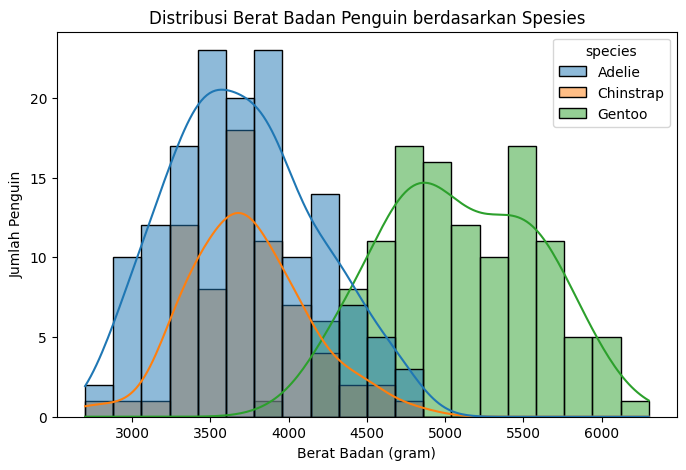

In [41]:
df_clean = df.dropna()

plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x='body_mass_g', hue='species', kde=True, bins=20)

plt.title('Distribusi Berat Badan Penguin berdasarkan Spesies')
plt.xlabel('Berat Badan (gram)')
plt.ylabel('Jumlah Penguin')
plt.show()

#### Temuan
Distribusi ukuran fisik penguin (body_mass_g dan culmen_length_mm) menunjukkan pola yang memiliki lebih dari satu puncak. Hal ini mengindikasikan adanya pengelompokkan alami berdasarkan perbedaan spesies atau jenis kelamin

### Visualisasi 2
Heatmap korelasi antar fitur

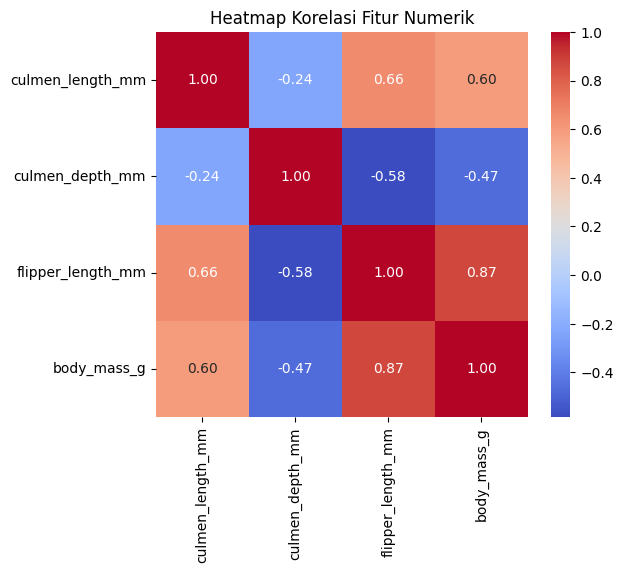

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

#### Temuan
Terdapat korelasi positif yang kuat antara **body_mass_g** dengan **flipper_length_mm** dan **culmen_length_mm**. Ini menunjukkan bahwa semakin panjangnya sirip dan paruh penguin, maka semakin berat pula bobot tubuhnya. Sebaliknya, **culmen_depth_mm** cenderung memiliki korelasi lebih rendah terhadap berat badan

###Visualisasi 3
Scatter plot


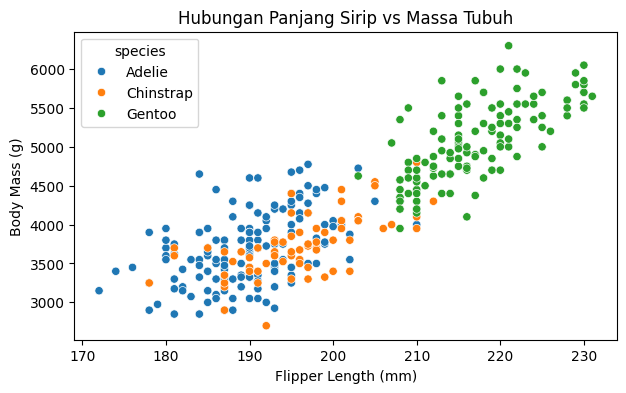

In [ ]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species')
plt.title('Hubungan Panjang Sirip vs Massa Tubuh')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.show()

#### Temuan
Grafik scatter plot melihatkan hubungan linear positif yang jelas antara **culmen_length_mm** (bisa juga dengan **flipper_length_mm**) dengan **body_mass_g**. Pengelompokkan warna berdasarkan spesies juga menunjukkan bahwa spesies Gentoo secara konsisten memiliki bobot tubuh dan ukuran fisik yang lebih besar dibanding Adelie dan Chinstrap

##A3. Preprocessing

In [42]:
print("Missing values awal:")
print(df.isnull().sum())

df_clean = df.dropna().copy()
df_clean = df_clean[df_clean['sex'].isin(['MALE', 'FEMALE'])]

print("Jumlah data duplikat: ", df_clean.duplicated().sum())

df_encoded = pd.get_dummies(
    df_clean, columns=['species', 'island', 'sex'], drop_first=True, dtype=int
)

print("\nHasil encoding 5 baris pertama:")
df_encoded.head()

Missing values awal:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
Jumlah data duplikat:  0

Hasil encoding 5 baris pertama:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species_Chinstrap,species_Gentoo,island_Dream,island_Torgersen,sex_MALE
0,39.1,18.7,181.0,3750.0,0,0,0,1,1
1,39.5,17.4,186.0,3800.0,0,0,0,1,0
2,40.3,18.0,195.0,3250.0,0,0,0,1,0
4,36.7,19.3,193.0,3450.0,0,0,0,1,0
5,39.3,20.6,190.0,3650.0,0,0,0,1,1


Proses pembersihan data dilakukan dengan menghapus nilai kosong NaN, memfilter kategori tak valid pada kolom sex, mengonfirmasi ketiadaan data duplikat, serta menerapkan *one-hot encoding* bertipe integer pada seluruh variabel kategorikal.

In [43]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
for col in numeric_cols:
  Q1 = df_encoded[col].quantile(0.25)
  Q3 = df_encoded[col].quantile(0.75)
  IQR = Q3 - Q1
  df_encoded = df_encoded[(df_encoded[col] >= Q1 - 1.5 * IQR) & (df_encoded[col] <= Q3 + 1.5 * IQR)]

df_encoded = df_encoded.reset_index(drop=True)

scaler = StandardScaler()
scale_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm']

df_scaled = df_encoded.copy()
df_scaled[scale_cols] = scaler.fit_transform(df_scaled[scale_cols])

df_scaled.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species_Chinstrap,species_Gentoo,island_Dream,island_Torgersen,sex_MALE
0,-0.896042,0.780732,-1.426752,3750.0,0,0,0,1,1
1,-0.822788,0.119584,-1.069474,3800.0,0,0,0,1,0
2,-0.676280,0.424729,-0.426373,3250.0,0,0,0,1,0
3,-1.335566,1.085877,-0.569284,3450.0,0,0,0,1,0
4,-0.859415,1.747026,-0.783651,3650.0,0,0,0,1,1


Proses ini mencakup pembersihan nilai outlier ekstrem pada fitur numerik menggunakan metode IQR serta standardisasi skala fitur numerik independen menggunakan StandardScaler.

#A4. Pemilihan Fitur

Berdasarkan analisis korelasi dan pengujian Variance Inflation Factor (VIF), fitur **flipper_length_mm**, **culmen_length_mm**, **sex_MALE**, dan **species_Gentoo** dipertahankan karena terbukti memiliki korelasi linier yang kuat serta kontribusi paling signifikan terhadap massa tubuh penguin tanpa masalah multikolinearitas (VIF < 5).

Sebaliknya, fitur **island_Dream**, **island_Torgersen**, dan **culmen_depth_mm** dibuang dari model karena memiliki korelasi yang rendah serta berpotensi redundan.

Sementara itu, variabel **sex_FEMALE**, **species_Adelie**, dan **island_Biscoe** tidak dimasukkan secara terpisah karena berperan sebagai kategori acuan (baseline)

##A5. Pembagian Data

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ['culmen_length_mm', 'flipper_length_mm', 'species_Gentoo', 'sex_MALE']
X = df_encoded[features]
y = df_encoded['body_mass_g']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

Jumlah data latih: 266
Jumlah data uji: 67


Tahap ini memisahkan fitur terpilih dan target, membagi dataset menjadi data latih (80%) dan data uji (20%), serta menerapkan standardisasi (StandardScaler) pada fitur untuk mencegah kebocoran data.

## A6. Pemodelan

In [48]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Intercept: ", round(model.intercept_, 2))
print("Koefisien: ")
coef_df = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_})
display(coef_df)

Intercept:  4214.76
Koefisien: 


,Fitur,Koefisien
0,culmen_length_mm,7.348168
1,flipper_length_mm,235.744547
2,species_Gentoo,454.367270
3,sex_MALE,271.017893


Nilai intercept menunjukkan estimasi rata-rata bobot dasar penguin, sementara koefisien bernilai positif pada seluruh fitur terpilih (flipper_length_mm, culmen_length_mm, species_Gentoo, dan sex_MALE) mengindikasikan bahwa semakin besar ukuran fisik serta adanya atribut spesies Gentoo maupuun jenis kelamin jantan akan secara langsung meningkatkan prediksi massa tubuh penguin dalam satuan gram.

##A7. Evaluasi

In [25]:
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

Melakukan prediksi nilai massa tubuh (body_mass_g) pada data latih dan data uji menggunakan fitur yang telah discale.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

mae_tr, mse_tr, rmse_tr, r2_tr = get_metrics(y_train, y_train_pred)
mae_te, mse_te, rmse_te, r2_te = get_metrics(y_test, y_test_pred)

print(f"Data Latih -> MAE: {mae_tr:.2f} | MSE: {mse_tr:.2f} | RMSE: {rmse_tr:.2f} | R2: {r2_tr:.4f}")
print(f"Data Uji   -> MAE: {mae_te:.2f} | MSE: {mse_te:.2f} | RMSE: {rmse_te:.2f} | R2: {r2_te:.4f}")

Data Latih -> MAE: 233.16 | MSE: 84539.59 | RMSE: 290.76 | R2: 0.8708
Data Uji   -> MAE: 197.67 | MSE: 65013.41 | RMSE: 254.98 | R2: 0.8936


Menghitung dan menampilkan metrik evaluasi (MAE, MSE, RMSE, dan $R^2$) untuk data latih dan data uji guna mengevaluasi akurasi serta mendeteksi indikasi overfitting atau underfitting.

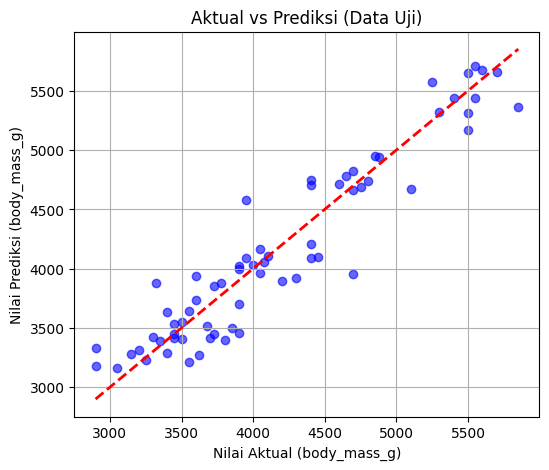

In [29]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_test_pred, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Aktual vs Prediksi (Data Uji)')
plt.xlabel('Nilai Aktual (body_mass_g)')
plt.ylabel('Nilai Prediksi (body_mass_g)')
plt.grid(True)
plt.show()

Menampilkan scatter plot antara nilai aktual dan nilai prediksi pada data uji untuk melihat tingkat kesesuaian prediksi terhadap garis ideal (y = x).

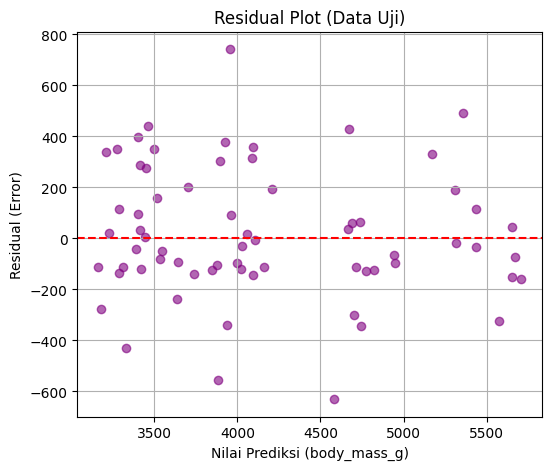

In [30]:
residuals = y_test - y_test_pred

plt.figure(figsize=(6, 5))
plt.scatter(y_test_pred, residuals, color='purple', alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residual Plot (Data Uji)')
plt.xlabel('Nilai Prediksi (body_mass_g)')
plt.ylabel('Residual (Error)')
plt.grid(True)
plt.show()

Menampilkan sebaran sisaan (residual) terhadap nilai prediksi untuk mengevaluasi asumsi linearitas dan homoscedasticity (kesamaan varians eror).



1.   Analisis Metrik Evaluasi
*   R$^2$ = nilai R$^2$ pada data uji mencapai 0,8936 (89,36%), yang menunjukkan bahwa variabel independen mampu menjelaskan sebagian besar variabilitas massa tubuh penguin.
*   MAE & RMSE = Model memiliki rata-rata MAE sebesar 197,67 gram, dan RMSE sebesar 254,98 gram pada data uji. Angka error ini tergolong rendah mengingat rentang berat badan penguin berada di kisaran 3000 - 6000 gram.
*   Indikasi Generalisasi = Performa pada data uji yang seimbang dengan data latih (R$^2$ latih = 0,8708 vs uji = 0,8936) mengindikasikan bahwa model memiliki kemampuan generalisasi yang sangat baik tanpa mengalami overfitting.




2.   Analisis Visualisasi Grafik


*   Grafik Aktual vs Prediksi = Titik-titik data menyebar secara merapat di sekitar garis diagonal y = x, yang menandakan kesesuaian tinggi antara nilai prediksi model dengan kondisi aktual di lapangan
*   Residual Plot = residual tersebar secaar acak di sekitar garis 0 (y = 0) tanpa membentuk pola apapun. Hal ini membuktikan bahwa asumsi linearitas dan homoscedasticity (varians error konstan) terpenuhi.




##A8. Analisis Performa

Model terindikasi good fitting tanpa overfitting dengan tingkat akurasi yang tinggi (R$^2$ = 0,8936), di mana **species_Gentoo** dan **flipper_length_mm** menjadi variabel paling dominan yang berpengaruh positif terhadap massa tubuh penguin walaupun memiliki keterbatasan karena datanya hanya mencakup tiga spesies penguin di Palmer Archipelago.